Pedro Domitti de Carvalho - 21005320

Considere o data set 'iris-with-errors.csv'







In [1231]:
import numpy as np
import scipy.stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [1232]:
data = pd.read_csv('../data/iris-with-errors.csv')

In [1233]:
# 1) Qual a dimensão do data set (ou seja, quantas variáveis são consideradas? quantas observações são consideradas?)

# Dataset dimensions
data.shape

# Variables: 5
# Observations: 25

(25, 5)

In [1234]:
# 2) Verifique se existem valores ausentes no dataset. Em caso positivo os remova.

# Missing values
print('Missing values:')
print(data.isnull().sum())

# Removing missing values
data = data.dropna()

# Clean values
print('\nMissing values after cleaning:')
print(data.isnull().sum())

Missing values:
sepal_length    2
sepal_width     0
petal_length    0
petal_width     1
species         0
dtype: int64

Missing values after cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [1235]:
# 3) Verifique se existem linhas duplicadas no dataset. Em caso positivo os remova.

# Duplicated lines
print('Duplicated lines:')
print(data.duplicated().sum())

# Removing duplicated lines
data = data.drop_duplicates()

# Clean lines
print('\nDuplicated lines after cleaning:')
print(data.duplicated().sum())

Duplicated lines:
5

Duplicated lines after cleaning:
0


In [1236]:
# 4) Utilizando o comando head exiba o dataset. Existe algum dado que indica um possível erro?
# Em caso positivo é possível substituir esse dado por um Nan (not a number): Para isso utilize a seguinte estrutura
# data = data.replace('simbolo a ser substituido', np.nan)

import numpy as np

# Original dataset
print('Original dataset:')
print(data.head())

# Replacing error data by NaN
data = data.replace('?', np.nan)

# Corrected dataset
print('\nCorrected dataset:')
print(data.head())

Original dataset:
  sepal_length sepal_width  petal_length petal_width    species
0          5.1         3.5           1.4         0.2  duplicada
2            ?           3           1.4         0.2     setosa
3          4.7         3.2           1.3         0.2     setosa
6            5         3.6           1.4         0.2     setosa
7          5.4         3.9           1.7         0.4  duplicada

Corrected dataset:
  sepal_length sepal_width  petal_length petal_width    species
0          5.1         3.5           1.4         0.2  duplicada
2          NaN           3           1.4         0.2     setosa
3          4.7         3.2           1.3         0.2     setosa
6            5         3.6           1.4         0.2     setosa
7          5.4         3.9           1.7         0.4  duplicada


In [1237]:
# 5) Após a etapa aterior substitua os valores Nan pela média de cada atributo.

# Dataset with NaN
print('Dataset with NaN:')
print(data.head(5))

for col in data.columns:
    if data[col].dtype == 'float64':
        data[col] = data[col].fillna(data[col].mean())
    else:
        data[col] = data[col].fillna(data[col].mode()[0])

# Dataset with NaN replaced by mean
print('\nDataset with NaN replaced by mean:')
print(data.head(5))

Dataset with NaN:
  sepal_length sepal_width  petal_length petal_width    species
0          5.1         3.5           1.4         0.2  duplicada
2          NaN           3           1.4         0.2     setosa
3          4.7         3.2           1.3         0.2     setosa
6            5         3.6           1.4         0.2     setosa
7          5.4         3.9           1.7         0.4  duplicada

Dataset with NaN replaced by mean:
  sepal_length sepal_width  petal_length petal_width    species
0          5.1         3.5           1.4         0.2  duplicada
2          5.4           3           1.4         0.2     setosa
3          4.7         3.2           1.3         0.2     setosa
6            5         3.6           1.4         0.2     setosa
7          5.4         3.9           1.7         0.4  duplicada


In [1238]:
# 6) Transforme o atributo categórico qualitativo em um atributo numérico

data['species'] = data['species'].astype('category').cat.codes
data['species']

0     0
2     1
3     1
6     1
7     0
10    1
11    0
12    1
13    1
15    1
16    1
18    1
19    1
20    1
21    1
22    1
23    1
Name: species, dtype: int8

Considere agora o data set iris.csv

In [1239]:
data = pd.read_csv('../data/iris.csv')

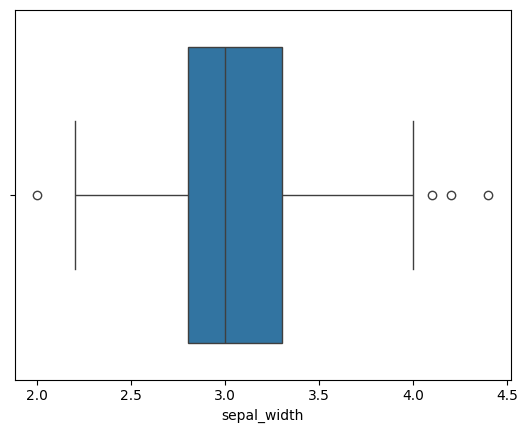

/tmp/ipykernel_8710/4044357633.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = data['sepal_width'].groupby(bins)


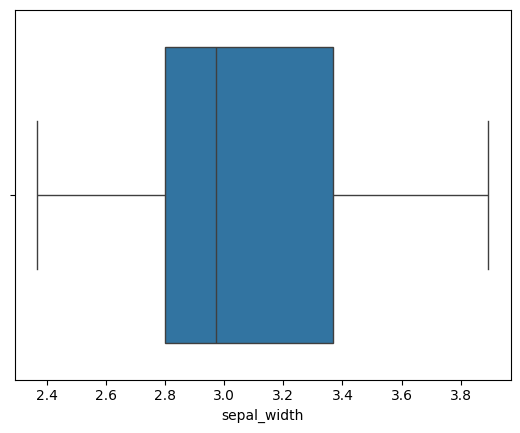

In [1240]:
# 7) Existem valores ruidosos para a variável 'sepal_width'? Em caso positivo os remova.

# Boxplot with noisy values
sns.boxplot(x=data['sepal_width'])
plt.show()

# Removing noisy values
bins = pd.qcut(data['sepal_width'], 10, duplicates='drop')
groups = data['sepal_width'].groupby(bins)
means = groups.mean()
new_sepal_width = bins.apply(lambda x : means[x])
data['sepal_width'] = new_sepal_width

# Boxplot without noisy values
sns.boxplot(x=data['sepal_width'])
plt.show()

In [1241]:
# 8) Qual o tamanho de amostra deve ser obtida para garantir um erro máximo de 5%?

# Sample size
n = data.count()[0]

# Error
e = 0.05

n0 = 1 / (e ** 2)

sample_size = (n * n0) / (n + n0)

print('Tamanho da amostra para erro máximo de 5%:', round(sample_size))

Tamanho da amostra para erro máximo de 5%: 109


/tmp/ipykernel_8710/818891985.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  n = data.count()[0]


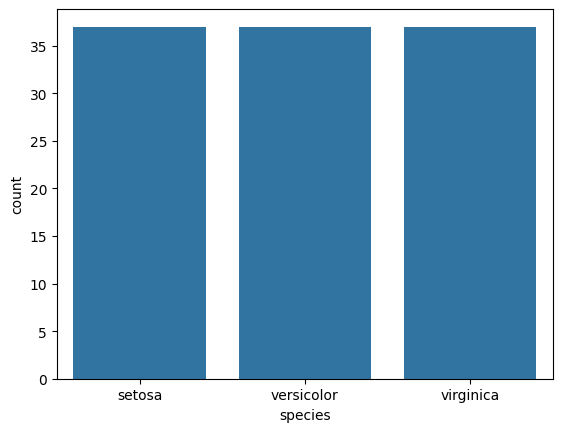

In [1242]:
# 9) Obtenha uma amostra proporcional estratificada para o dataset considerando o tamanho da amostra obtido no exercício 8.

sample_size = 110
classes = data['species'].unique()
quantity_per_class = round(sample_size / len(classes))
samples_per_class = []

# Proportional stratified sample
for c in classes:
    samples_per_class.append(data[data['species'] == c].sample(quantity_per_class))

sample = pd.concat(samples_per_class)

sns.countplot(x='species', data=sample)
plt.show()